# 01 - Data acquisition & EDA
Heart Disease UCI (Cleveland) dataset. Run top to bottom.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # repo root (notebook lives in notebooks/)
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 30)

In [2]:
from scripts.download_data import main as download  # downloads + cleans
import sys; sys.argv = ['download']
download()

INFO Downloading https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
INFO Saved raw data (303 rows) to C:\Users\Debabrata\OneDrive\Desktop\MLOps\heart-disease-mlops\heart-disease-mlops\data\raw\heart_disease_raw.csv
INFO Saved cleaned data (303 rows) to C:\Users\Debabrata\OneDrive\Desktop\MLOps\heart-disease-mlops\heart-disease-mlops\data\processed\heart_disease_clean.csv


Cleaned dataset: 303 rows x 14 columns
target
no disease    164
disease       139
Name: count, dtype: int64


In [3]:
from src.data import load_raw_data, load_clean_data
raw = load_raw_data(); clean = load_clean_data()
print(raw.shape, clean.shape)
raw.head()

(303, 14) (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Missing values & data types (raw)

In [4]:
display(raw.isna().sum().to_frame('missing'))
raw.dtypes.to_frame('dtype')

,missing
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


,dtype
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64


## Cleaned data summary

In [5]:
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Generate all EDA figures

INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical un

01_missing_values.png


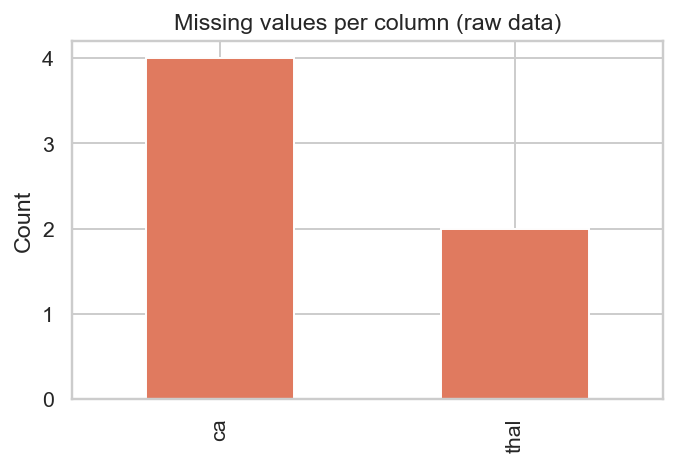

02_class_balance.png


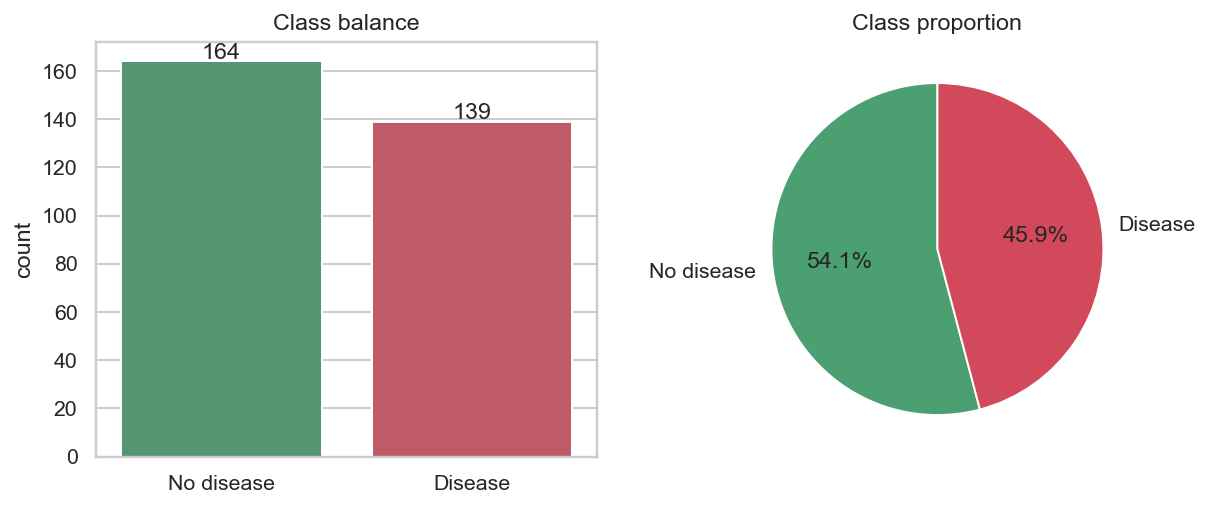

03_numeric_histograms.png


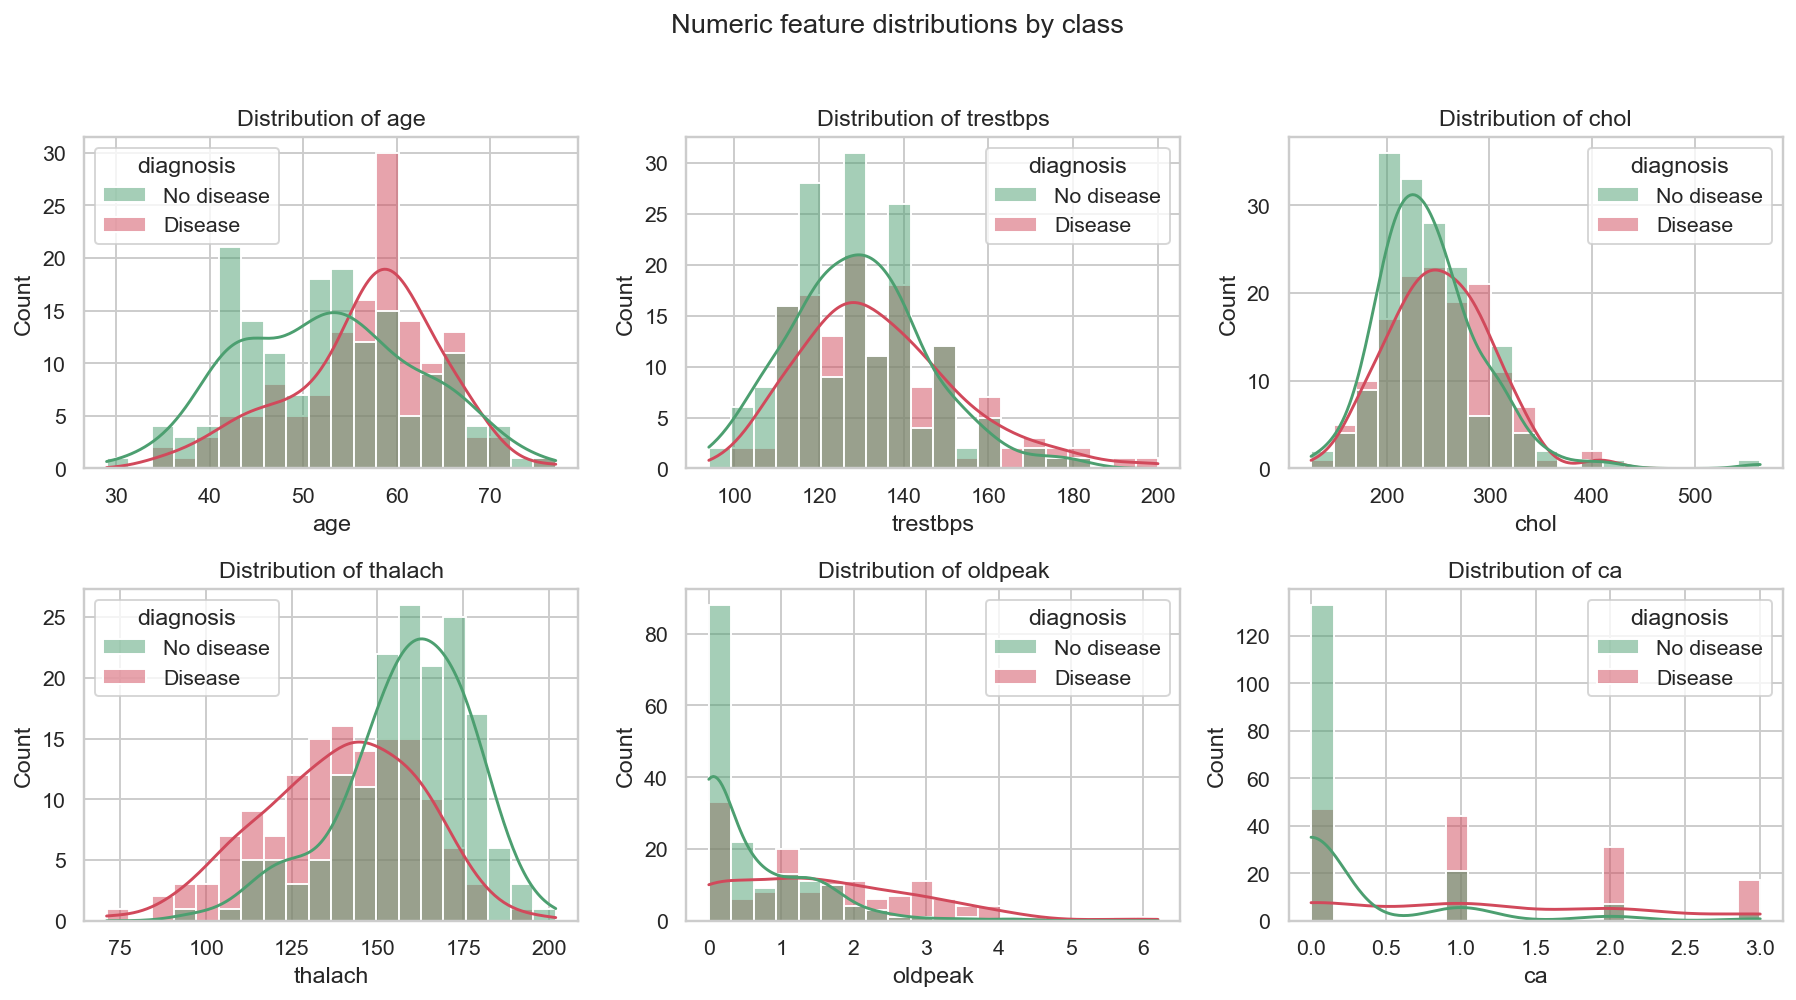

04_numeric_boxplots.png


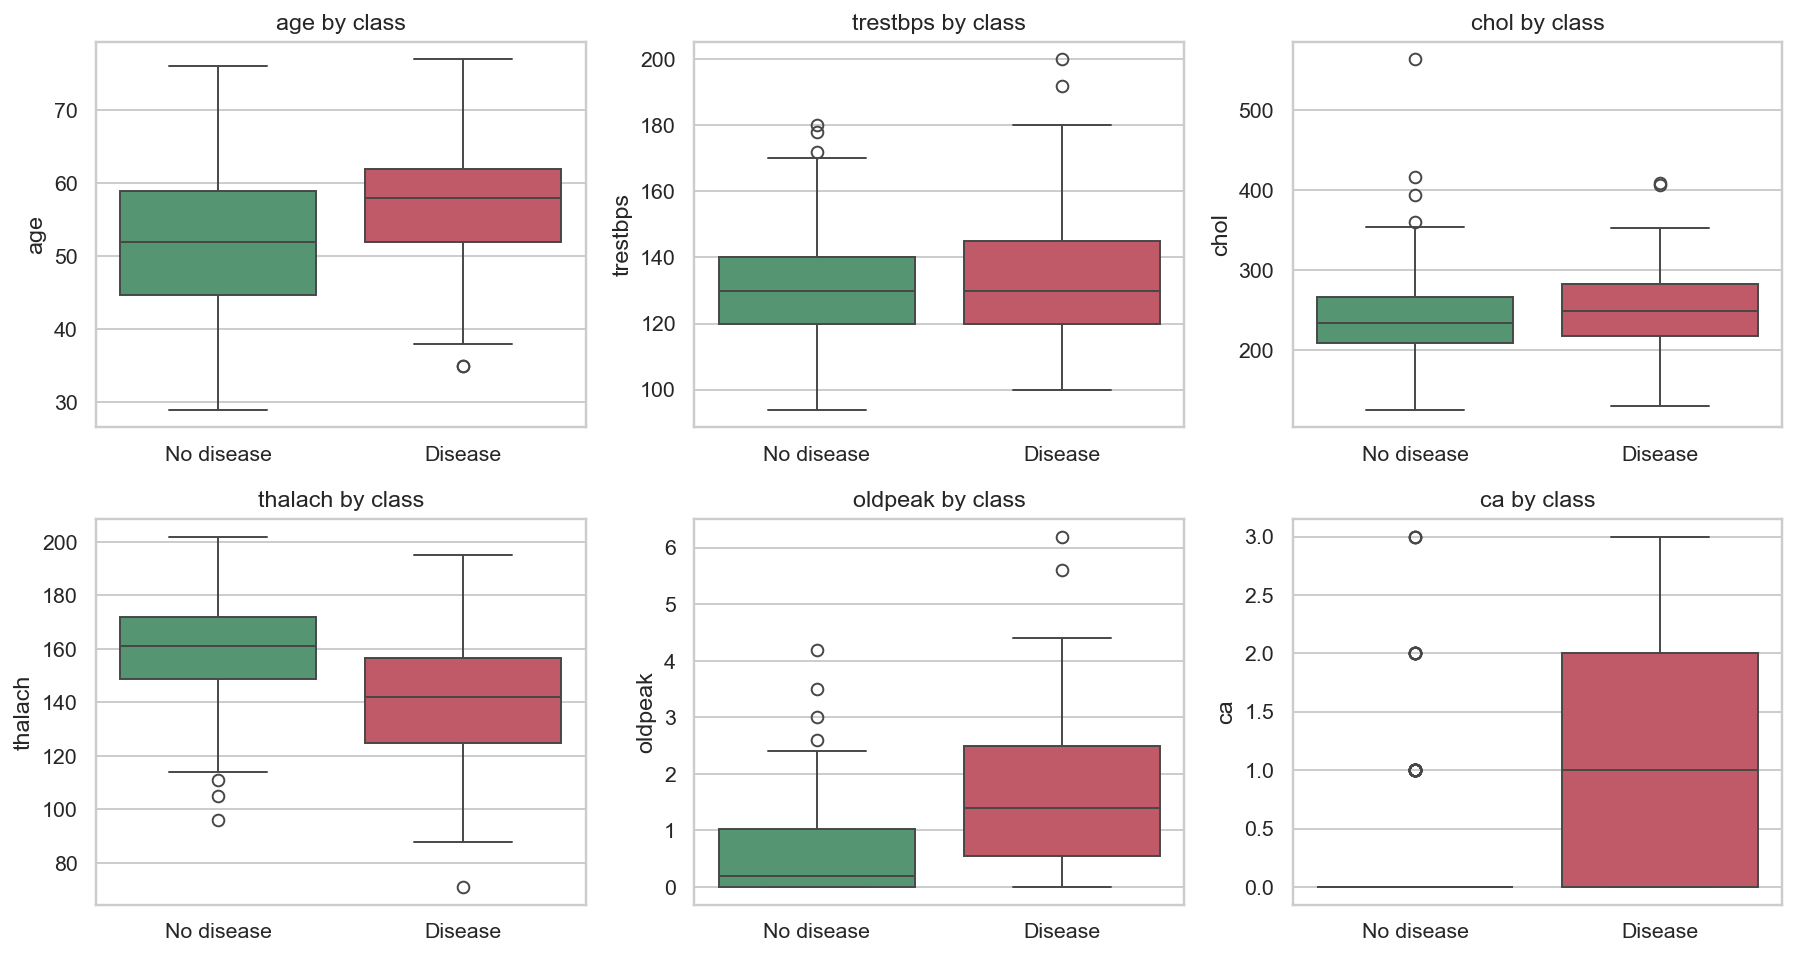

05_categorical_counts.png


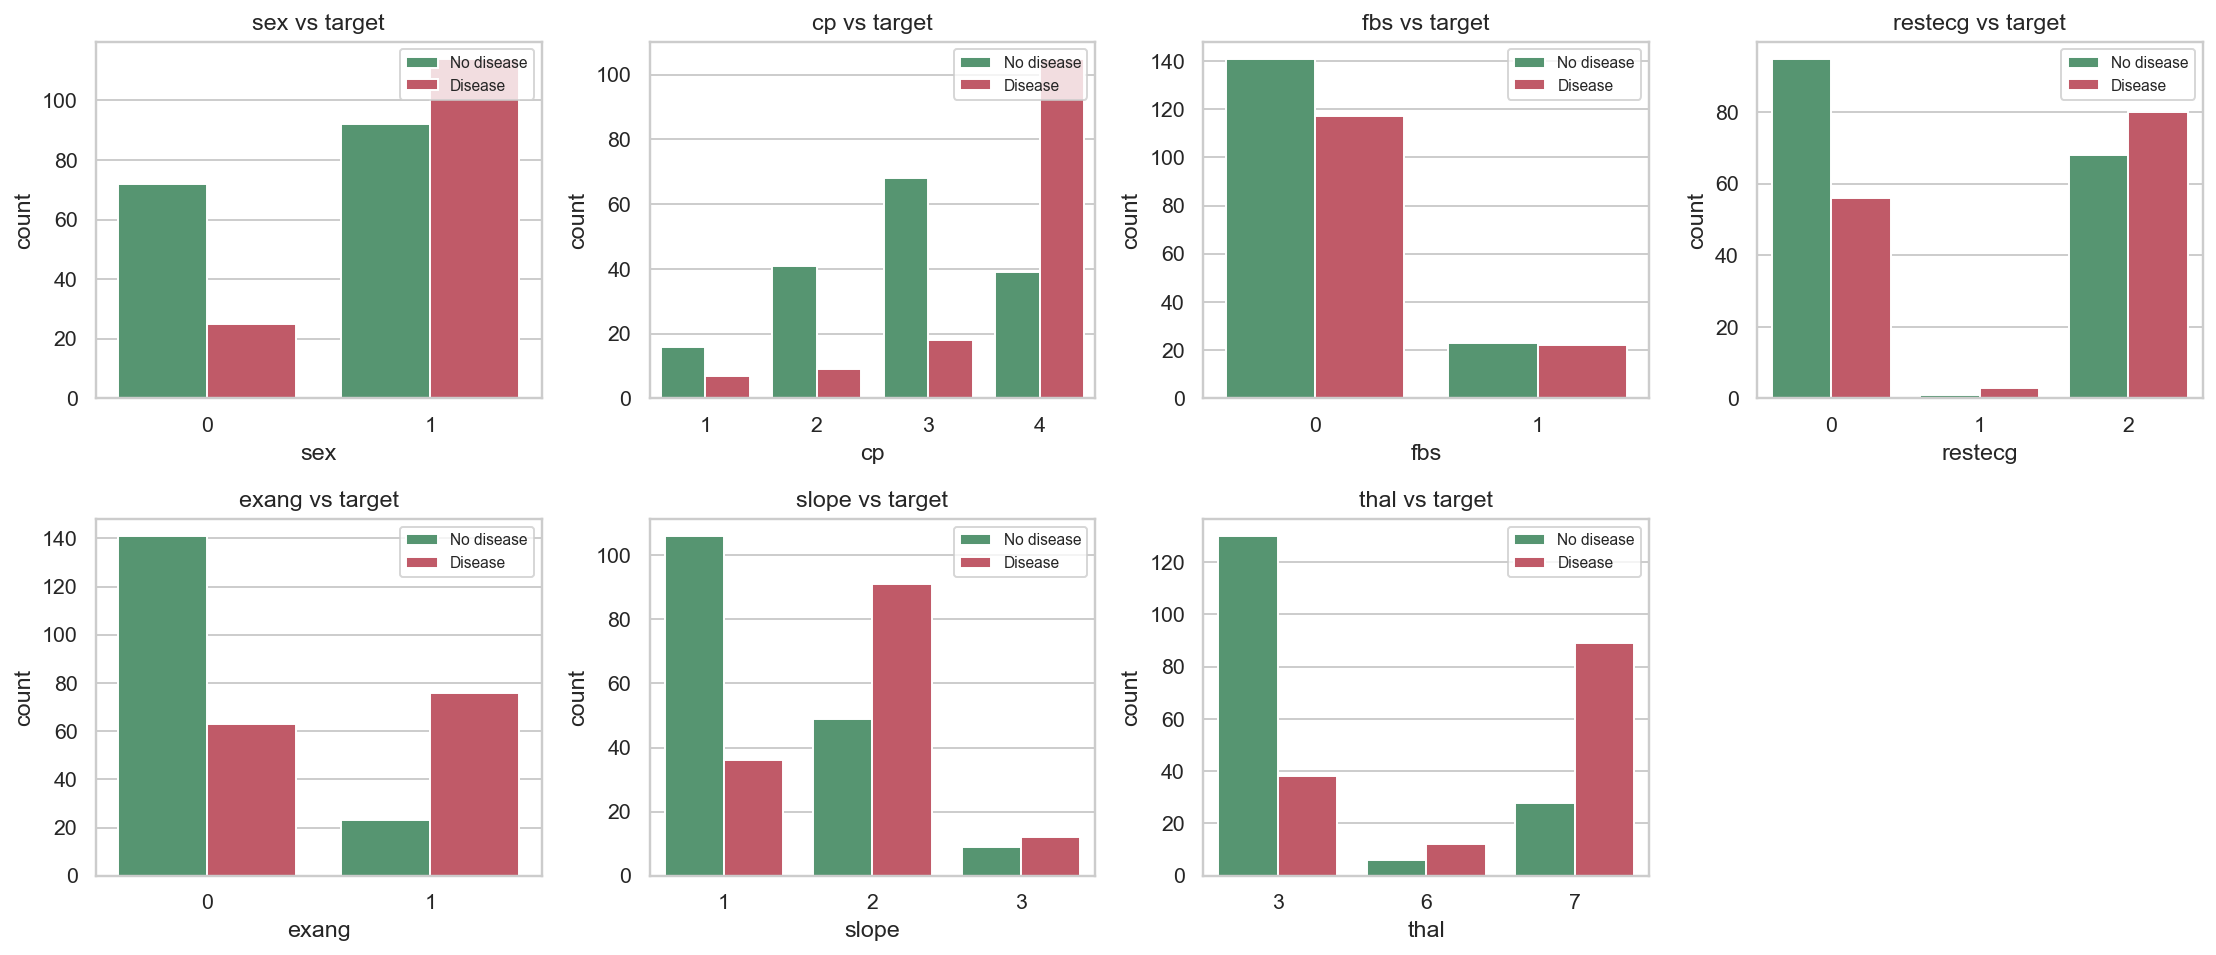

06_correlation_heatmap.png


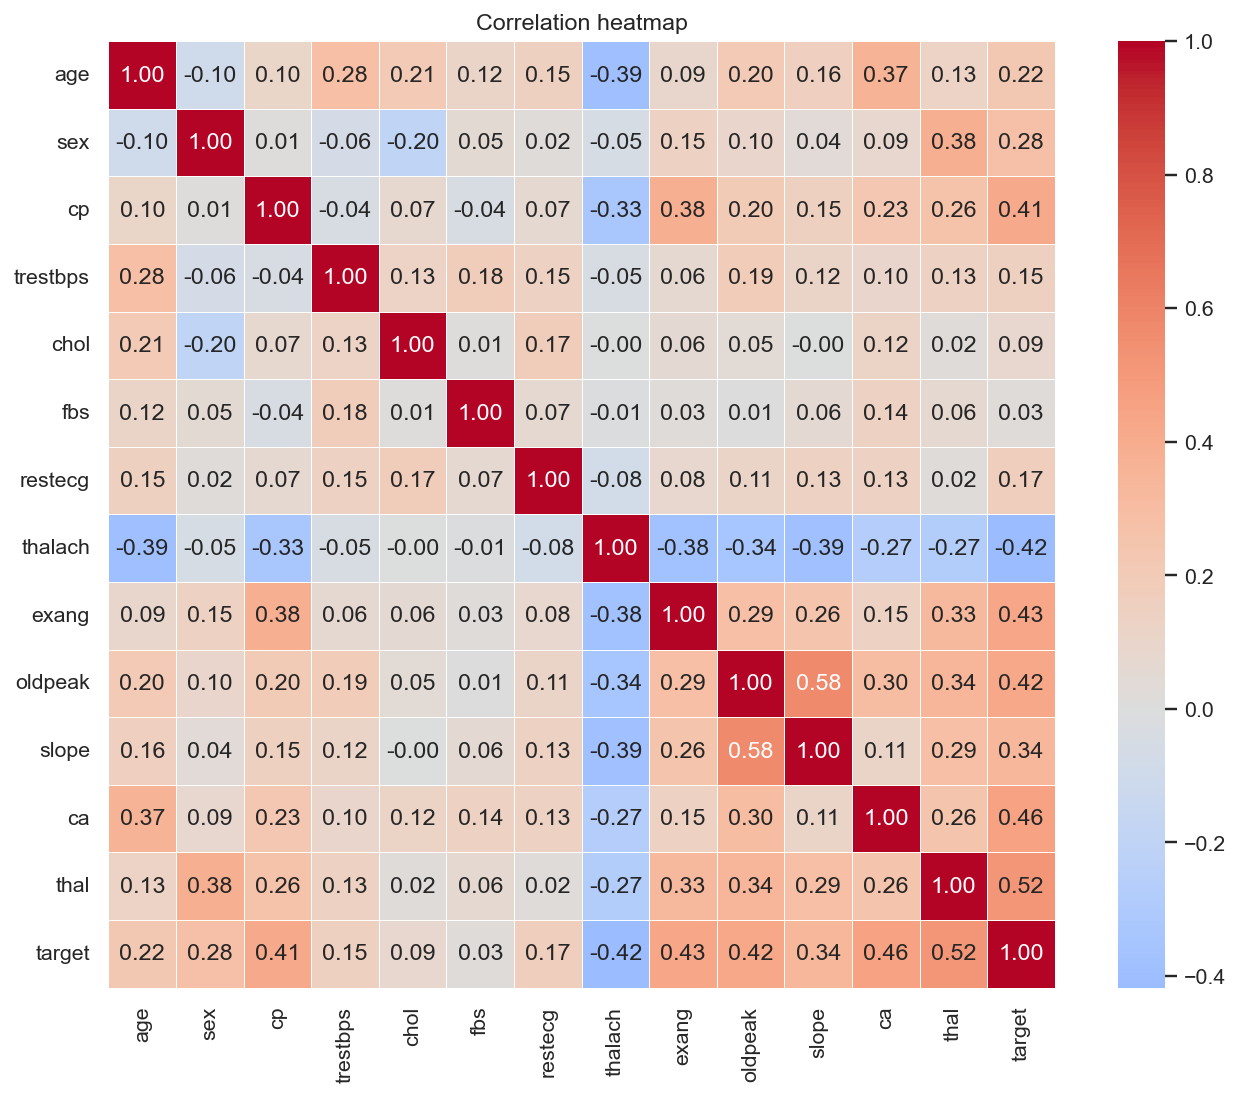

07_target_correlation.png


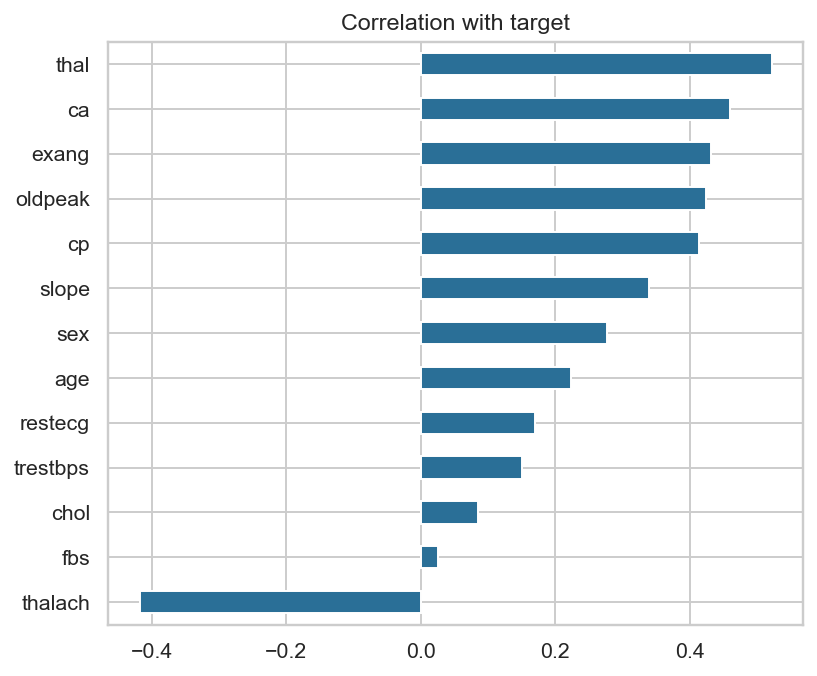

In [6]:
from src.eda import run_eda
for p in run_eda():
    print(p.name); display(Image(filename=str(p)))